## Logistic Regression 

In [3]:
""" Input Features
      │
      ▼
Linear Equation
(z = w₁x₁ + w₂x₂ + ... + b)
      │
      ▼
Sigmoid Function
      │
      ▼
Probability (0 to 1)
      │
      ▼
Threshold (0.5)
      │
      ▼
Class 0 or Class 1"""


' Input Features\n      │\n      ▼\nLinear Equation\n(z = w₁x₁ + w₂x₂ + ... + b)\n      │\n      ▼\nSigmoid Function\n      │\n      ▼\nProbability (0 to 1)\n      │\n      ▼\nThreshold (0.5)\n      │\n      ▼\nClass 0 or Class 1'

### Imports

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

In [14]:
data = pd.read_csv("students_score_logistic.csv") 
data.head()

,Hours_Studied,Pass
0,1,0
1,2,0
2,3,0
3,4,0
4,5,1


### Explore the Data

In [16]:
data.shape

(10, 2)

In [18]:
data.columns

Index(['Hours_Studied', 'Pass'], dtype='object')

In [20]:
data.dtypes

Hours_Studied    int64
Pass             int64
dtype: object

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Hours_Studied  10 non-null     int64
 1   Pass           10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes


In [23]:
data.describe()

,Hours_Studied,Pass
count,10.00000,10.000000
mean,5.50000,0.600000
std,3.02765,0.516398
min,1.00000,0.000000
25%,3.25000,0.000000
50%,5.50000,1.000000
75%,7.75000,1.000000
max,10.00000,1.000000


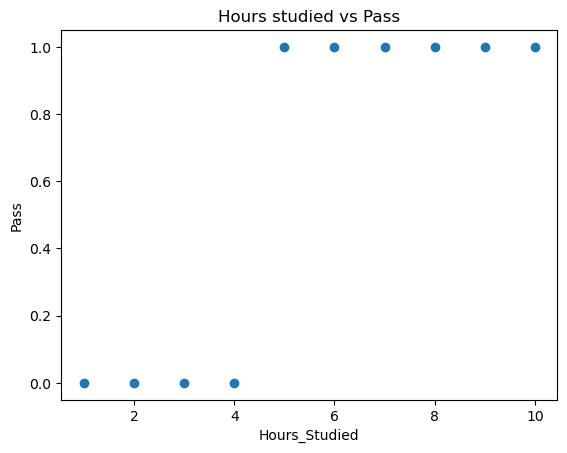

In [25]:
plt.scatter(
    data["Hours_Studied"], #x-axis
    data["Pass"]) # y-axis
plt.xlabel("Hours_Studied")
plt.ylabel("Pass")
plt.title("Hours studied vs Pass")

plt.show()

In [26]:
x = data[["Hours_Studied"]]
y = data["Pass"]

### Training the model

In [27]:
model = LogisticRegression()
model.fit(x,y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [30]:
model.predict_proba(x) #will give probability of fail(0) and probalibity of pass(1)

array([[0.9841674 , 0.0158326 ],
       [0.95015825, 0.04984175],
       [0.85393783, 0.14606217],
       [0.64195893, 0.35804107],
       [0.35478473, 0.64521527],
       [0.14430039, 0.85569961],
       [0.04917374, 0.95082626],
       [0.01561291, 0.98438709],
       [0.00484057, 0.99515943],
       [0.00148951, 0.99851049]])

In [32]:
print(model.predict(x))

[0 0 0 0 1 1 1 1 1 1]


In [34]:
probabilities = model.predict_proba(x)[:, 1]

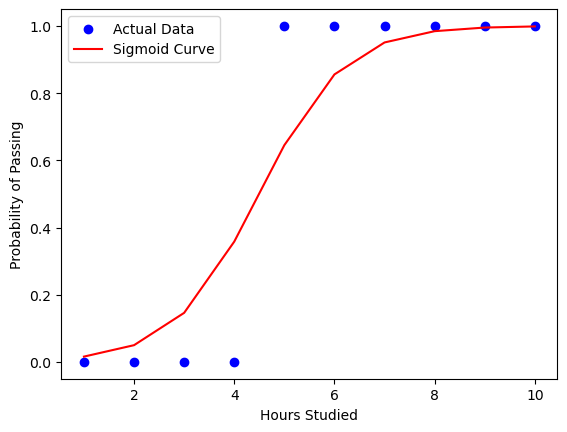

In [36]:
plt.scatter(x, y, color="blue", label="Actual Data")

plt.plot(x, probabilities, color="red", label="Sigmoid Curve")

plt.xlabel("Hours Studied")
plt.ylabel("Probability of Passing")

plt.legend()

plt.show()

In [38]:
y_pred = model.predict(x)

print(y_pred)

[0 0 0 0 1 1 1 1 1 1]


In [40]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y,y_pred) # accuracy = Out of all predictions, how many were correct. 
# accuracy = no.of correct predictions/total predictions

print("Accuracy:", accuracy)

Accuracy: 1.0


### Confusion Matrix

In [42]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, y_pred)
print(cm)

[[4 0]
 [0 6]]


In [43]:
from sklearn.metrics import classification_report

print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10

